In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import xarray as xr
import dask
from dask.diagnostics import ProgressBar

import pvlib
from src.conversion_energy.pv import (
    DEFAULT_PV_CONFIGURATION,
    NORMALISED_ROOFTOP_PV_CONFIGURATION,
    ROOFTOP_PV_CONFIGURATION,
    compute_pv_from_config,
)
from src.data_processing.load_data import ClimateModelData, ClimateReanalysisData
from src.utils.utils_xarray import (
    get_time_resolution,
    match_instaneous_to_mean_values,
    match_time_steps,
    match_time_steps_interpolate,
    sel_extent,
)

from src.utils.constants import BC_SUBDAILY_CHUNKS

sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
dask.config.set(num_workers=15, scheduler="processes")

dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

In [4]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"

path_figs = Path(paths["path_figs"])

In [7]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [8]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

# Load data

In [10]:
ds_rsds_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "rsds.zarr",
    extent=extent,
    chunks=BC_SUBDAILY_CHUNKS,
)

ds_tas_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr",
    extent=extent_ch,
    chunks=BC_SUBDAILY_CHUNKS,
)

ds_sfcWind_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "sfcWind.zarr",
    extent=extent_ch,
    chunks=BC_SUBDAILY_CHUNKS,
)

ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    extent=extent_ch,
)
ds_orog = ds_orog.chunk(
    {k: v for k, v in BC_SUBDAILY_CHUNKS.items() if k in ds_orog.dims}
)

In [11]:
# ...existing code...
def match_instaneous_to_mean_values_trapazoidal(
    ds_data: xr.Dataset,
    skip_leap_days: bool = True,
    time_res: str = "1h",
) -> xr.Dataset:
    """
    Compute window means assuming linear evolution between samples,
    without densifying to an hourly grid.

    This is equivalent to: (linear interpolation to any dense grid) + resample(...).mean(),
    but faster/more memory-friendly:
      1) Build union of original timestamps and target window edges.
      2) Linearly interpolate only at those timestamps.
      3) Integrate with trapezoids over each adjacent pair.
      4) Sum per target window and divide by window duration.

    Parameters
    ----------
    ds_data : xr.Dataset with a 'time' coordinate
    skip_leap_days : bool
        Drop Feb-29 timestamps in the final output (matches your previous behavior).
    time_res : str
        Target window, e.g. "3h", "1D".

    Returns
    -------
    xr.Dataset
        Time-mean over each window (label='left', closed='left'), same as
        hourly-interp + resample mean under a linear-in-time assumption.
    """
    # Ensure monotonic time
    ds_data = ds_data.sortby("time")

    # Window edges (label='left', closed='left' behavior)
    t0 = pd.Timestamp(ds_data.time.values[0])
    t1 = pd.Timestamp(ds_data.time.values[-1])
    edges = pd.date_range(t0.floor(time_res), t1.ceil(time_res), freq=time_res)

    # Union of original times and window edges (unique & sorted)
    union = xr.DataArray(
        np.unique(np.concatenate([ds_data.time.values, edges.values])),
        dims="time",
        name="time",
    )

    # Interpolate only at union points (piecewise-linear assumption)
    ds_lin = ds_data.interp(time=union)

    # Trapezoid integration over successive pairs
    dt = (ds_lin.time.diff("time") / np.timedelta64(1, "s")).rename("dt")  # seconds
    left = ds_lin.isel(time=slice(0, -1))
    right = ds_lin.isel(time=slice(1, None))

    # 0.5 * (f(t_i) + f(t_{i+1})) * dt_i  for every segment
    seg_int = 0.5 * (left + right)
    # Broadcast dt to all variables
    seg_int = seg_int * dt

    # Sum segment integrals per target window (segment is labeled by its left time)
    window_seconds = pd.to_timedelta(time_res).total_seconds()
    ds_mean = seg_int.resample(time=time_res, label="left", closed="left").sum() / window_seconds

    if skip_leap_days:
        ds_mean = ds_mean.sel(time=~((ds_mean["time.month"] == 2) & (ds_mean["time.day"] == 29)))

    return ds_mean

all(match_instaneous_to_mean_values_trapazoidal(
    ds_tas_bc.ds_data.isel(time=slice(None, 8), lat=0, lon=0),
    skip_leap_days=True,
    time_res="3h",
).tas == ds_tas_bc.ds_data.isel(time=slice(None, 8), lat=0, lon=0).rolling(
    time=2, center=True, min_periods=1
).construct("window").mean("window").tas)

KeyboardInterrupt: 

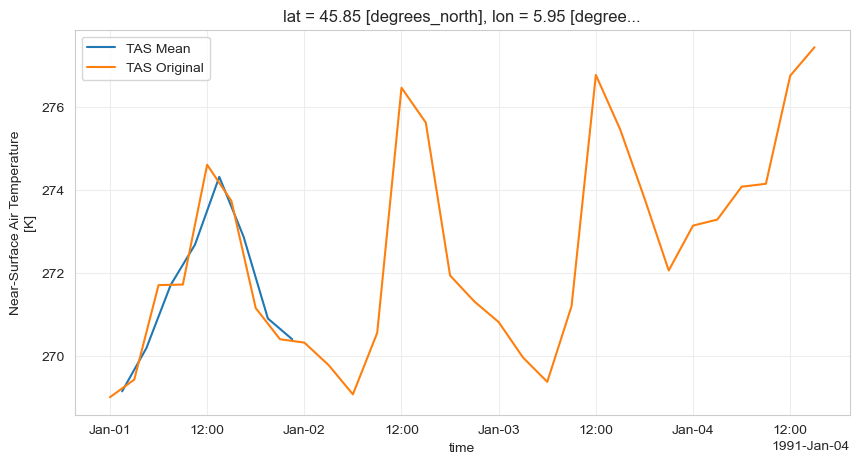

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
match_instaneous_to_mean_values(
    ds_tas_bc.ds_data.isel(time=slice(None, 8), lat=0, lon=0),
    skip_leap_days=True,
    time_res="3h",
).tas.assign_coords(
    time=ds_tas_bc.ds_data.isel(time=slice(None, 8)).time
    + pd.Timedelta(hours=1, minutes=30)
).plot(ax=ax, label="TAS Mean")
# match_instaneous_to_mean_values_trapazoidal(
#     ds_tas_bc.ds_data.isel(time=slice(None, 8), lat=0, lon=0),
#     skip_leap_days=True,
#     time_res="3h",
# ).tas.plot(ax=ax, label="TAS Trapozoidal Mean")
# ds_tas_bc.ds_data.isel(time=slice(None, 30), lat=0, lon=0).rolling(
#     time=2, center=True, min_periods=1
# ).construct("window").mean("window").tas.plot(ax=ax, label="TAS Rolling Mean")
ds_tas_bc.ds_data.isel(time=slice(None, 30), lat=0, lon=0).tas.plot(
    ax=ax, label="TAS Original"
)
plt.legend()
plt.show()

In [ ]:
time_slice = slice("1991", "1993")
ds_tas_bc.ds_data = ds_tas_bc.ds_data.sel(time=time_slice)
ds_sfcWind_bc.ds_data = ds_sfcWind_bc.ds_data.sel(time=time_slice)
ds_rsds_bc.ds_data = ds_rsds_bc.ds_data.sel(time=time_slice)

print("Matching instantaneous to mean values")

with ProgressBar(dt=1):
    ds_tas_bc.ds_data = match_instaneous_to_mean_values(
        ds_tas_bc.ds_data - 273.15, skip_leap_days=True, time_res="3h"
    ).persist()
    ds_tas_bc.ds_data["time"] = ds_tas_bc.ds_data["time"] + pd.Timedelta(
        hours=1, minutes=30
    )

    ds_sfcWind_bc.ds_data = match_instaneous_to_mean_values(
        ds_sfcWind_bc.ds_data, skip_leap_days=True, time_res="3h"
    ).persist()
    ds_sfcWind_bc.ds_data["time"] = ds_sfcWind_bc.ds_data["time"] + pd.Timedelta(
        hours=1, minutes=30
    )

Matching instantaneous to mean values
[###########################             ] | 69% Completed | 24m 34ss

Process SpawnProcess-38:
Process SpawnProcess-36:
Process SpawnProcess-33:
Traceback (most recent call last):
  File "/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/concurrent/futures/process.py", line 249, in _process_worker
    call_item = call_queue.get(block=True)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/multiprocessing/queues.py", line 103, in get
    res = self._recv_bytes()
          ^^^^^^^^^^^^^^^^^^
  File "/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/multiprocessing/connection.py", line 216, in recv_bytes
    buf = self._recv_bytes(maxlength)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^

[###########################             ] | 69% Completed | 24m 36s


KeyboardInterrupt: 

In [ ]:
tilt = 35
azimuth = 180
direction = "S"
with ProgressBar(dt=1):
    ds_pv = (
        compute_pv_from_config(
            ds_rsds_bc.ds_data.rsds.chunk({"time": -1}),
            ds_tas_bc.ds_data.tas.chunk({"time": -1}),
            ds_sfcWind_bc.ds_data.sfcWind.chunk({"time": -1}),
            tilt=tilt,
            azimuth=azimuth,
            pv_configuration=NORMALISED_ROOFTOP_PV_CONFIGURATION,
            altitude=ds_orog.orog,
        ).rename({"ac_power": f"tilt_{tilt}_azimuth_{direction}"})
        / NORMALISED_ROOFTOP_PV_CONFIGURATION["module_parameters"]["pdc0"]
    ).compute()

[########################################] | 100% Completed | 129.24 s


In [ ]:
ds_pv_benchmark = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/energy/ch/pv/pv_CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85.zarr",
    chunks="auto",
).sel(time=slice("1991", "1993"))[[f"tilt_{tilt}_azimuth_{direction}"]]

In [ ]:
ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr"
).ds_data.isel(time=slice(0, 10))

<xarray.Dataset> Size: 12MB
Dimensions:  (lat: 426, lon: 710, time: 10)
Coordinates:
  * lat      (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon      (lon) float64 6kB -29.95 -29.85 -29.75 -29.65 ... 40.75 40.85 40.95
  * time     (time) datetime64[ns] 80B 1991-01-01T03:00:00 ... 1991-01-02T09:...
Data variables:
    tas      (time, lat, lon) float32 12MB ...
Attributes: (12/32)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

In [ ]:
models = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1",
    "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1",
    "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1",
    "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1",
]

for model in models:
    ds_tas_benchmark = ClimateModelData(
        path_data_processed
        / "cordex_processed"
        / f"{model}_{climate_scenario}"
        / "bias_corrected"
        / "3hr"
        / "psl.zarr"
    ).ds_data.isel(time=slice(0, 20))
    first_time_step = pd.to_datetime(ds_tas_benchmark.time.values[0])
    print(first_time_step)
    hours = get_valid_hours(get_time_resolution(ds_tas_benchmark), first_time_step.hour)
    print(hours)

1991-01-01 03:00:00
[3, 6, 9, 12, 15, 18, 21]
1991-01-01 00:00:00
[0, 3, 6, 9, 12, 15, 18, 21]
1991-01-01 00:00:00
[0, 3, 6, 9, 12, 15, 18, 21]
1991-01-01 00:00:00
[0, 3, 6, 9, 12, 15, 18, 21]
1991-01-01 00:00:00
[0, 3, 6, 9, 12, 15, 18, 21]


In [ ]:
climate_model_chain = "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1"
ds_rsds_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "rsds.zarr",
    # extent=extent,
    chunks="auto",
)

ds_tas_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr",
    # extent=extent,
    chunks="auto",
)

ds_sfcWind_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "sfcWind.zarr",
    # extent=extent,
    chunks="auto",
)

Frozen({'time': (2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920, 2920), 'lat': (128, 128, 128, 42), 'lon': (128, 128, 128, 76)})


In [ ]:
ds_pv_benchmark_regridded = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
    / "3hr"
    / "tas.zarr"
).ds_data.sel(time=slice("1991", "1993"))

In [ ]:
from src.utils.utils_xarray import get_valid_hours, get_time_resolution

first_time_step = pd.to_datetime(ds_pv_benchmark_regridded.time.values[0])
hours = get_valid_hours(
    get_time_resolution(ds_pv_benchmark_regridded), first_time_step.hour
)

In [ ]:
hours

[0, 3, 6, 9, 12, 15, 18, 21]